# UTS Data Acquisition & Management
## Pariwisata Surabaya: Kunjungan Wisatawan per Destinasi dan Cuaca Bulanan

| | |
|---|---|
| Nama / NIM | I Gede Raditya Ananda Putra / 2501010024 |
| Mata kuliah | Data Acquisition & Management, Informatika, Kelas E, INSTIKI (Dosen: Dr. I Gede Totok Suryawan, S.Kom., M.T.) |
| (a) Berkas | **data.go.id**: *Banyaknya Kunjungan Wisatawan Nusantara dan Wisatawan Mancanegara menurut Tempat Wisata* (Kota Surabaya), CSV dihosting di ckan.surabaya.go.id |
| (b) API | Open-Meteo Historical Weather (archive) API, tanpa API key |
| (c) Scraping | Wikipedia bahasa Indonesia: *Daftar kecamatan dan kelurahan di Kota Surabaya* |

**Alur:** Setup, Soal 1 (baca dan identifikasi), Soal 2 (lisensi, PII, etika), Soal 3 (API), Soal 4 (robots.txt dan scraping), Soal 5 (merge), Ringkasan.
Data mentah ada di `data/raw/` dan **tidak pernah diubah**; jika berkas mentah sudah ada, notebook memakai salinan itu dan memverifikasi MD5-nya. Hasil olahan ada di `data/processed/`.

### Menjalankan di Google Colab
Siapkan folder `MyDrive/uts_dam/` di Google Drive dengan isi:
```
uts_dam/
├── uts_dam.ipynb
├── scripts/verify_submission.py
└── data/raw/banyaknya-wisman-wisnus-2026.csv   <- unduhan manual, nama persis sama
```
Buka `uts_dam.ipynb` di Colab, lalu **Runtime, Run all** dan izinkan akses Drive. Tidak perlu `.env`: di Colab, email kontak otomatis memakai email kampus `mahasiswa@instiki.ac.id` (di komputer lokal, isi `CONTACT_EMAIL` di `.env` atau environment variable).

## 0. Setup
Dua sel: (1) pustaka, folder, dan **User-Agent berisi email kampus** (dicetak lengkap sebagai bukti), (2) fungsi bantu: `etis_get()` (timeout, jeda per host, retry dengan *exponential backoff* untuk 429/5xx, log status), `md5_file()`, `simpan_mentah()` (tidak menimpa data mentah), `catat_provenance()`, `ambil_atau_pakai()`, dan `baca_robots()`.

In [1]:
# ===== SETUP 1/2: lingkungan, pustaka, folder proyek, dan identitas (User-Agent) =====
import hashlib, io, itertools, json, os, platform, re, subprocess, sys, time, urllib.robotparser
from datetime import date, datetime, timedelta, timezone
from pathlib import Path
from urllib.parse import urlparse

# Google Colab: pasang pustaka yang kadang belum ada, sambungkan Drive, lalu pindah ke folder uts_dam/
try:
    from google.colab import drive
    DI_COLAB = True
except ImportError:
    DI_COLAB = False                       # berjalan di komputer lokal
if DI_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-dotenv", "lxml"], check=False)
    drive.mount("/content/drive")
    if not os.path.isdir("/content/drive/MyDrive/uts_dam"):
        raise SystemExit("Folder MyDrive/uts_dam tidak ditemukan. Buat folder itu dan isi sesuai petunjuk di atas.")
    os.chdir("/content/drive/MyDrive/uts_dam")   # pengganti %cd

import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup
from dotenv import load_dotenv

# Folder proyek: semua path relatif terhadap folder kerja; data mentah (raw) tidak pernah diubah
BASE_DIR = Path.cwd()
RAW_DIR, PROCESSED_DIR = BASE_DIR / "data" / "raw", BASE_DIR / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
WIB = timezone(timedelta(hours=7))                  # zona waktu untuk mencatat tanggal akses
pd.set_option("display.max_columns", None)          # tampilkan semua kolom agar bukti tidak terpotong
pd.set_option("display.width", 200)

# Email kontak: environment variable dulu, lalu berkas .env, lalu (khusus Colab) email kampus
SUMBER_KONTAK = "environment variable" if os.environ.get("CONTACT_EMAIL", "").strip() else ".env"
load_dotenv(BASE_DIR / ".env", override=False)
CONTACT_EMAIL = os.getenv("CONTACT_EMAIL", "").strip()
if not CONTACT_EMAIL and DI_COLAB:
    CONTACT_EMAIL, SUMBER_KONTAK = "mahasiswa@instiki.ac.id", "email kampus (default di Colab)"
if not CONTACT_EMAIL or "@" not in CONTACT_EMAIL or CONTACT_EMAIL.endswith("example.com"):
    raise SystemExit("CONTACT_EMAIL kosong. Isi di .env (lihat .env.example) atau set environment variable CONTACT_EMAIL.")

# User-Agent jujur: nama klien, tujuan akademik, dan kontak yang bisa dihubungi pemilik situs
USER_AGENT = ("UTS-DAM-INSTIKI/1.0 (tugas kuliah Data Acquisition & Management; "
              f"kontak: {CONTACT_EMAIL}) python-requests/{requests.__version__}")

print("Lingkungan :", "Google Colab" if DI_COLAB else "lokal", "| Python", platform.python_version(),
      "| pandas", pd.__version__, "| requests", requests.__version__)
print("Folder kerja:", BASE_DIR)
print("Sumber CONTACT_EMAIL:", SUMBER_KONTAK)
print("User-Agent yang dipakai:")
print(USER_AGENT)

Lingkungan : lokal | Python 3.13.18 | pandas 3.0.5 | requests 2.34.2
Folder kerja: /tmp/uji
Sumber CONTACT_EMAIL: environment variable
User-Agent yang dipakai:
UTS-DAM-INSTIKI/1.0 (tugas kuliah Data Acquisition & Management; kontak: mahasiswa@instiki.ac.id) python-requests/2.34.2


In [2]:
# Parameter etika request: timeout (connect, read), jeda minimum per host, dan batas retry
TIMEOUT = (10, 60)          # detik: 10 untuk koneksi, 60 untuk membaca respons
JEDA_DEFAULT = 2.0          # detik jeda minimum antar-request ke host yang sama
JEDA_PER_HOST = {}          # diisi dari Crawl-delay robots.txt bila ada (mis. CKAN Surabaya)
MAKS_RETRY = 4              # jumlah percobaan ulang untuk 429/5xx
STATUS_RETRY = {429, 500, 502, 503, 504}

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": USER_AGENT})

LOG_REQUEST = []            # log semua request: waktu, host, URL, status, durasi, percobaan
_terakhir_per_host = {}     # waktu request terakhir per host untuk menegakkan jeda


def etis_get(url, params=None, jeda=None):
    """GET yang etis: timeout, UA berkontak, jeda per host, retry + exponential backoff, log status."""
    host = urlparse(url).netloc
    jeda_min = jeda if jeda is not None else JEDA_PER_HOST.get(host, JEDA_DEFAULT)
    for percobaan in range(1, MAKS_RETRY + 2):
        # Tegakkan jeda minimum sejak request terakhir ke host yang sama
        sejak = time.monotonic() - _terakhir_per_host.get(host, -1e9)
        if sejak < jeda_min:
            time.sleep(jeda_min - sejak)
        mulai = time.monotonic()
        try:
            resp = SESSION.get(url, params=params, timeout=TIMEOUT)
            status = resp.status_code
        except requests.RequestException as err:
            resp, status = None, f"ERROR {type(err).__name__}"
        _terakhir_per_host[host] = time.monotonic()
        LOG_REQUEST.append({
            "waktu": datetime.now(WIB).strftime("%Y-%m-%d %H:%M:%S%z"),
            "host": host,
            "url": (resp.url if resp is not None else url)[:120],
            "status": status,
            "durasi_s": round(time.monotonic() - mulai, 2),
            "percobaan": percobaan,
        })
        print(f"[{status}] percobaan {percobaan} {host}{urlparse(url).path[:70]}")
        # Sukses atau error klien selain 429: kembalikan/hentikan tanpa retry
        if resp is not None and status not in STATUS_RETRY:
            resp.raise_for_status()
            return resp
        if percobaan > MAKS_RETRY:
            break
        # Exponential backoff: 2, 4, 8, 16 detik; pakai Retry-After jika server memintanya
        tunggu = 2 ** percobaan
        if resp is not None and resp.headers.get("Retry-After", "").isdigit():
            tunggu = max(tunggu, int(resp.headers["Retry-After"]))
        print(f"    -> status {status}, menunggu {tunggu} detik sebelum mencoba lagi")
        time.sleep(tunggu)
    pesan = resp.text[:200] if resp is not None else ""
    raise RuntimeError(f"Gagal mengambil {url} setelah {MAKS_RETRY + 1} percobaan "
                       f"(status terakhir {status}). {pesan}")


def md5_file(path, ukuran_blok=65536):
    """Hitung hash MD5 sebuah berkas secara bertahap (hemat memori)."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(ukuran_blok), b""):
            h.update(blok)
    return h.hexdigest()


def simpan_mentah(path, isi_bytes):
    """Simpan data mentah SEKALI saja; berkas yang sudah ada tidak boleh ditimpa."""
    if path.exists():
        raise FileExistsError(f"{path} sudah ada — data mentah tidak boleh ditimpa")
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(isi_bytes)


PROVENANCE = []
KOLOM_PROVENANCE = ["sumber_id", "peran", "jenis", "katalog", "url", "url_unduhan", "dataset_id",
                    "organisasi_penerbit", "host_berkas", "tanggal_akses", "asal_tanggal_akses", "lisensi",
                    "path_lokal", "ukuran_byte", "md5", "cara_perolehan", "bukti", "catatan"]


def catat_provenance(sumber_id, path, **isian):
    """Catat satu baris provenance; ukuran dan MD5 dihitung dari berkas, kolom lain diisi lewat argumen."""
    baris = {k: "-" for k in KOLOM_PROVENANCE}
    baris.update({k: v for k, v in isian.items() if k in KOLOM_PROVENANCE})
    baris.update({"sumber_id": sumber_id, "path_lokal": str(Path(path).relative_to(BASE_DIR)),
                  "ukuran_byte": Path(path).stat().st_size, "md5": md5_file(path)})
    # Ganti entri lama dengan sumber_id yang sama agar sel bisa dijalankan ulang tanpa duplikasi
    PROVENANCE[:] = [p for p in PROVENANCE if p["sumber_id"] != sumber_id] + [baris]
    return baris


def ambil_atau_pakai(path, url, params=None, jeda=None):
    """Unduh ke data/raw jika belum ada; jika sudah ada, pakai salinan lama (raw tidak diubah).
    Mengembalikan (bytes, tanggal_akses). Tanggal akses berkas lama dibaca dari berkas .akses."""
    catatan_akses = path.with_name(path.name + ".akses")
    if path.exists():
        print(f"Berkas mentah sudah ada, tidak diunduh ulang: {path.relative_to(BASE_DIR)}")
        return path.read_bytes(), catatan_akses.read_text(encoding="utf-8").strip()
    resp = etis_get(url, params=params, jeda=jeda)
    tanggal = datetime.now(WIB).strftime("%Y-%m-%d %H:%M:%S%z")
    simpan_mentah(path, resp.content)
    catatan_akses.write_text(tanggal + "\n", encoding="utf-8")
    print(f"Disimpan: {path.relative_to(BASE_DIR)} ({len(resp.content):,} byte)")
    return resp.content, tanggal


def baca_robots(url_robots, path_simpan, jeda=None):
    """Ambil robots.txt dengan etis_get, simpan mentah, lalu parse dengan urllib.robotparser."""
    isi, tanggal = ambil_atau_pakai(path_simpan, url_robots, jeda=jeda)
    teks = isi.decode("utf-8-sig", errors="replace")  # utf-8-sig membuang BOM di awal berkas (ada di robots.txt Wikipedia)
    rp = urllib.robotparser.RobotFileParser()
    rp.set_url(url_robots)
    rp.parse(teks.splitlines())
    return rp, teks, tanggal


print("Fungsi siap: etis_get, md5_file, simpan_mentah, catat_provenance, ambil_atau_pakai, baca_robots")

Fungsi siap: etis_get, md5_file, simpan_mentah, catat_provenance, ambil_atau_pakai, baca_robots


## 1. Soal 1: Berkas dataset (bobot 20%)
Berkas diunduh **manual lewat peramban** dari halaman dataset di **data.go.id** (17 November 2026; bukti: `docs/bukti_metadata_data_go_id_2026-11-17.png`).

| Peran | Pihak |
|---|---|
| Katalog (sumber yang diizinkan soal) | data.go.id |
| Host berkas | ckan.surabaya.go.id |
| Penerbit asli | Pemerintah Kota Surabaya |

**Parameter `pd.read_csv`** (dipilih setelah memeriksa byte mentah):

| Parameter | Nilai | Alasan |
|---|---|---|
| `sep` | `";"` | Header berisi titik koma, tanpa koma |
| `encoding` | `"utf-8"` | Semua ASCII, tanpa BOM; ditulis eksplisit agar sama di semua sistem |
| `dtype` | kode wilayah `str`; jumlah dan tahun `int64` | Kode adalah label, bukan besaran; `int64` sekaligus memvalidasi angka |
| `na_values`, `thousands`, `skiprows` | tidak dipakai | Tidak ada sel kosong, pemisah ribuan, atau baris judul; nilai `0` adalah kunjungan nol yang sah |

In [3]:
# ===== SOAL 1.1: sumber utama dan pemeriksaan berkas =====
# Metadata sumber utama (dicatat manual dari halaman data.go.id, 17 November 2026)
SUMBER_UTAMA = {
    "judul": "Banyaknya Kunjungan Wisatawan Nusantara dan Wisatawan Mancanegara menurut Tempat Wisata",
    "organisasi_portal": "Kota Surabaya",
    "dataset_id": "5c1cb1a5-8b39-42df-a8c3-48fff07fec6e",
    "url_halaman": ("https://data.go.id/dataset/dataset/banyaknya-kunjungan-wisatawan-nusantara-dan-"
                    "wisatawan-mancanegara-menurut-tempat-wisata-ta-2025"),
    "url_unduhan": ("https://ckan.surabaya.go.id/dataset/5c1cb1a5-8b39-42df-a8c3-48fff07fec6e/resource/"
                    "3a969972-e959-462d-b37b-cbdd14830f0b/download/banyaknya-wisman-wisnus-2026.csv"),
    "resource_id_ckan": "3a969972-e959-462d-b37b-cbdd14830f0b",
    "status_akses": "Terbuka",
    "dipublikasi": "25-09-2026",
    "dimodifikasi": "25-09-2026",
    "label_resource": "CSV, cakupan \"per Januari 2025 - Agustus 2026\"",
    "status_tautan": "URL Aktif (200), dicek portal 17 Nov 2026 10:36 WIB",
    "lisensi": ("Lisensi tidak dicantumkan pada tabel metadata halaman dataset data.go.id. "
                "Status akses di portal: Terbuka."),
    "metadata_portal": ("Tabel metadata tampil dengan isian kosong untuk semua kolom (Source s.d. Metode); "
                        "metadata portal belum lengkap."),
    "banner": "INFORMASI: Data berikut ini masih dalam proses pemenuhan Prinsip SDI.",
    "tanggal_unduh": "2026-11-17",
    "cara_perolehan": "unduhan manual lewat peramban oleh mahasiswa (tombol Download di data.go.id)",
    "bukti": "docs/bukti_metadata_data_go_id_2026-11-17.png",
}

# Berkas unduhan manual harus ada dengan nama persis sama, dan MD5-nya harus sama dengan yang tercatat
NAMA_BERKAS = "banyaknya-wisman-wisnus-2026.csv"
MD5_TERCATAT = "2658a38dff0ec62756fbd1147fd6914a"        # MD5 berkas yang diunduh manual, 17 Nov 2026
PATH_CSV = RAW_DIR / NAMA_BERKAS
hilang = [p for p in ("scripts/verify_submission.py", f"data/raw/{NAMA_BERKAS}") if not (BASE_DIR / p).exists()]
if hilang:
    raise SystemExit(f"Berkas wajib belum ada di folder proyek: {hilang}. Salin dengan nama persis sama.")
MD5_CSV = md5_file(PATH_CSV)
if MD5_CSV != MD5_TERCATAT:
    raise SystemExit("MD5 berkas CSV berbeda dari yang tercatat; pakai berkas unduhan asli, jangan simpan ulang di Excel.")
bukti_png = BASE_DIR / SUMBER_UTAMA["bukti"]
print("Berkas        :", PATH_CSV.relative_to(BASE_DIR), f"({PATH_CSV.stat().st_size:,} byte)")
print("MD5 (dihitung):", MD5_CSV, "= sama dengan MD5 tercatat")
print("Tangkapan layar metadata:", "ada" if bukti_png.exists() else "BELUM ADA (tambahkan sebelum mengumpulkan)")
pd.Series(SUMBER_UTAMA, name="nilai").to_frame()

Berkas        : data/raw/banyaknya-wisman-wisnus-2026.csv (26,881 byte)
MD5 (dihitung): 2658a38dff0ec62756fbd1147fd6914a = sama dengan MD5 tercatat
Tangkapan layar metadata: ada


,nilai
judul,Banyaknya Kunjungan Wisatawan Nusantara dan Wi...
organisasi_portal,Kota Surabaya
dataset_id,5c1cb1a5-8b39-42df-a8c3-48fff07fec6e
url_halaman,https://data.go.id/dataset/dataset/banyaknya-k...
url_unduhan,https://ckan.surabaya.go.id/dataset/5c1cb1a5-8...
resource_id_ckan,3a969972-e959-462d-b37b-cbdd14830f0b
status_akses,Terbuka
dipublikasi,25-09-2026
dimodifikasi,25-09-2026
label_resource,"CSV, cakupan ""per Januari 2025 - Agustus 2026"""


In [4]:
# ===== SOAL 1.2: periksa isi mentah, lalu baca CSV dengan parameter yang tepat =====
mentah = PATH_CSV.read_bytes()
baris_mentah = mentah.decode("utf-8").splitlines()
print("Diawali BOM UTF-8:", mentah.startswith(b"\xef\xbb\xbf"), "| semua byte ASCII:", all(b < 128 for b in mentah))
print("Baris CRLF       :", mentah.count(b"\r\n"), "dari", mentah.count(b"\n"))
print("Jumlah baris     :", len(baris_mentah), f"(1 header + {len(baris_mentah) - 1} data)")
print("Pemisah di header:", baris_mentah[0].count(";"), "titik koma dan", baris_mentah[0].count(","), "koma")
print("3 baris pertama  :", *baris_mentah[:3], sep="\n  ")

# Tipe tiap kolom: kode wilayah = teks (label, bukan angka untuk dihitung); jumlah kunjungan dan tahun = int
DTYPE_KUNJUNGAN = {"kode_propinsi": "str", "nama_propinsi": "str", "kode_kota": "str", "nama_kota": "str",
                   "nama_destinasi": "str", "wisman": "int64", "wisnus": "int64", "periode": "str", "tahun": "int64"}
df_kunjungan_raw = pd.read_csv(PATH_CSV, sep=";", encoding="utf-8", dtype=DTYPE_KUNJUNGAN)

# Bukti bahwa na_values dan thousands memang tidak diperlukan
teks = pd.read_csv(PATH_CSV, sep=";", encoding="utf-8", dtype=str, keep_default_na=False)
print("\nBentuk (baris, kolom):", df_kunjungan_raw.shape, "| minimal 100 baris:", len(df_kunjungan_raw) >= 100)
print("Sel kosong di teks mentah:", int((teks == "").sum().sum()), "| NaN setelah dibaca:", int(df_kunjungan_raw.isna().sum().sum()))
print("Ada titik/koma (pemisah ribuan) di kolom angka:",
      bool(teks[["wisman", "wisnus"]].apply(lambda s: s.str.contains(r"[.,]")).any().any()))
df_kunjungan_raw.head()

Diawali BOM UTF-8: False | semua byte ASCII: True
Baris CRLF       : 353 dari 353
Jumlah baris     : 353 (1 header + 352 data)
Pemisah di header: 8 titik koma dan 0 koma
3 baris pertama  :
  kode_propinsi;nama_propinsi;kode_kota;nama_kota;nama_destinasi;wisman;wisnus;periode;tahun
  35;JAWA TIMUR;3578;KOTA SURABAYA;SURABAYA SIGHTSEEING AND CITY TOUR (SSCT);0;312;Januari;2025
  35;JAWA TIMUR;3578;KOTA SURABAYA;TAMAN HIBURAN PANTAI KENJERAN;3;29935;Januari;2025

Bentuk (baris, kolom): (352, 9) | minimal 100 baris: True
Sel kosong di teks mentah: 0 | NaN setelah dibaca: 0
Ada titik/koma (pemisah ribuan) di kolom angka: False


,kode_propinsi,nama_propinsi,kode_kota,nama_kota,nama_destinasi,wisman,wisnus,periode,tahun
0,35,JAWA TIMUR,3578,KOTA SURABAYA,SURABAYA SIGHTSEEING AND CITY TOUR (SSCT),0,312,Januari,2025
1,35,JAWA TIMUR,3578,KOTA SURABAYA,TAMAN HIBURAN PANTAI KENJERAN,3,29935,Januari,2025
2,35,JAWA TIMUR,3578,KOTA SURABAYA,WISATA PERAHU KALIMAS,9,6118,Januari,2025
3,35,JAWA TIMUR,3578,KOTA SURABAYA,ALUN ALUN SURABAYA BALAI PEMUDA,25,48625,Januari,2025
4,35,JAWA TIMUR,3578,KOTA SURABAYA,MUSEUM TUGU PAHLAWAN,307,14332,Januari,2025


In [5]:
# ===== SOAL 1.3: identifikasi data =====
URUTAN_BULAN = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli",
                "Agustus", "September", "Oktober", "November", "Desember"]
no_bulan = {nama: i + 1 for i, nama in enumerate(URUTAN_BULAN)}

# Nama destinasi ada yang berspasi di ujung: dibersihkan HANYA pada salinan, data mentah dibiarkan
nama_asli = df_kunjungan_raw["nama_destinasi"]
ada_spasi = nama_asli != nama_asli.str.strip()
df_kunjungan_bersih = df_kunjungan_raw.copy()
df_kunjungan_bersih["nama_destinasi"] = nama_asli.str.strip()
JUMLAH_DESTINASI, BARIS_DISTRIP = df_kunjungan_bersih["nama_destinasi"].nunique(), int(ada_spasi.sum())
print(f"Nama destinasi unik: {nama_asli.nunique()} apa adanya, {JUMLAH_DESTINASI} setelah strip; baris berspasi: {BARIS_DISTRIP}")

# Makna dan satuan kolom (parafrase definisi di halaman data.go.id) + tipe, nilai unik, nol, kosong
makna = {
    "kode_propinsi": ("kode wilayah provinsi (Kemendagri/BPS)", "kode (label)"),
    "nama_propinsi": ("nama provinsi", "teks"),
    "kode_kota": ("kode wilayah kota (Kemendagri/BPS)", "kode (label)"),
    "nama_kota": ("nama kota", "teks"),
    "nama_destinasi": ("nama kawasan tujuan wisata", "teks"),
    "wisman": ("jumlah wisatawan mancanegara (orang asing, menginap < 1 tahun, bukan bekerja)", "orang per bulan"),
    "wisnus": ("jumlah wisatawan nusantara (penduduk Indonesia berwisata di dalam negeri)", "orang per bulan"),
    "periode": ("bulan pencatatan", "nama bulan (teks)"),
    "tahun": ("tahun pencatatan", "tahun (YYYY)"),
}
identifikasi = pd.DataFrame({
    "dtype": df_kunjungan_raw.dtypes.astype(str), "nilai_unik": df_kunjungan_raw.nunique(),
    "jumlah_nol": [(df_kunjungan_raw[c] == 0).sum() if df_kunjungan_raw[c].dtype.kind in "iu" else "-"
                   for c in df_kunjungan_raw.columns],
    "nilai_kosong": df_kunjungan_raw.isna().sum(),
    "makna": pd.Series({k: v[0] for k, v in makna.items()}), "satuan": pd.Series({k: v[1] for k, v in makna.items()}),
})
with pd.option_context("display.max_colwidth", 80):
    display(identifikasi)

# Ringkasan: jenis data, ukuran, cakupan wilayah dan waktu (semua dihitung dari berkas)
urut = df_kunjungan_raw.assign(b=df_kunjungan_raw["periode"].map(no_bulan)).sort_values(["tahun", "b"])
awal, akhir = urut.iloc[0], urut.iloc[-1]
ukuran_byte = PATH_CSV.stat().st_size
display(pd.Series({
    "Jenis data": "Terstruktur (tabular CSV, skema kolom tetap)",
    "Jumlah baris x kolom": f"{df_kunjungan_raw.shape[0]} x {df_kunjungan_raw.shape[1]}",
    "Cakupan wilayah": f"{awal['nama_kota'].title()}, {awal['nama_propinsi'].title()} ({JUMLAH_DESTINASI} destinasi)",
    "Cakupan waktu": f"{awal['periode']} {awal['tahun']} s.d. {akhir['periode']} {akhir['tahun']} (bulanan)",
    "Ukuran berkas": f"{ukuran_byte:,} byte ({ukuran_byte / 1024:.2f} KiB)",
    "Nilai nol wisman / wisnus": f"{(df_kunjungan_raw['wisman'] == 0).sum()} / {(df_kunjungan_raw['wisnus'] == 0).sum()}",
}, name="nilai").to_frame())

# Ketidakcocokan keterangan katalog data.go.id dengan isi berkas
periode_akhir, tahun_di_berkas = f"{akhir['periode']} {akhir['tahun']}", sorted(df_kunjungan_raw["tahun"].unique().tolist())
display(pd.DataFrame([
    ("Label cakupan resource", "per Januari 2025 - Agustus 2026", f"Januari 2025 - {periode_akhir}"),
    ("Tanggal metadata dimodifikasi", SUMBER_UTAMA["dimodifikasi"], f"berkas memuat data hingga {periode_akhir}"),
    ("Slug URL halaman", "...-ta-2025", f"berkas memuat tahun {tahun_di_berkas}"),
], columns=["aspek", "di katalog data.go.id", "di berkas (dihitung)"]))
CATATAN_KETIDAKCOCOKAN = (f"(1) label resource 'per Januari 2025 - Agustus 2026' tetapi berkas sampai {periode_akhir}; "
    f"(2) metadata dimodifikasi {SUMBER_UTAMA['dimodifikasi']} tetapi berkas memuat data {periode_akhir}; "
    f"(3) slug URL berakhiran '-ta-2025' tetapi berkas memuat tahun {tahun_di_berkas}. "
    "data.go.id = katalog; berkas dihosting di ckan.surabaya.go.id dan diperbarui tanpa metadata katalog ikut berubah.")

Nama destinasi unik: 17 apa adanya, 16 setelah strip; baris berspasi: 12


,dtype,nilai_unik,jumlah_nol,nilai_kosong,makna,satuan
kode_propinsi,str,1,-,0,kode wilayah provinsi (Kemendagri/BPS),kode (label)
nama_propinsi,str,1,-,0,nama provinsi,teks
kode_kota,str,1,-,0,kode wilayah kota (Kemendagri/BPS),kode (label)
nama_kota,str,1,-,0,nama kota,teks
nama_destinasi,str,17,-,0,nama kawasan tujuan wisata,teks
wisman,int64,95,124,0,"jumlah wisatawan mancanegara (orang asing, menginap < 1 tahun, bukan bekerja)",orang per bulan
wisnus,int64,283,7,0,jumlah wisatawan nusantara (penduduk Indonesia berwisata di dalam negeri),orang per bulan
periode,str,12,-,0,bulan pencatatan,nama bulan (teks)
tahun,int64,2,0,0,tahun pencatatan,tahun (YYYY)


,nilai
Jenis data,"Terstruktur (tabular CSV, skema kolom tetap)"
Jumlah baris x kolom,352 x 9
Cakupan wilayah,"Kota Surabaya, Jawa Timur (16 destinasi)"
Cakupan waktu,Januari 2025 s.d. Oktober 2026 (bulanan)
Ukuran berkas,"26,881 byte (26.25 KiB)"
Nilai nol wisman / wisnus,124 / 7


,aspek,di katalog data.go.id,di berkas (dihitung)
0,Label cakupan resource,per Januari 2025 - Agustus 2026,Januari 2025 - Oktober 2026
1,Tanggal metadata dimodifikasi,25-09-2026,berkas memuat data hingga Oktober 2026
2,Slug URL halaman,...-ta-2025,"berkas memuat tahun [2025, 2026]"


In [6]:
# ===== SOAL 1.4: tahun analisis dan kualitas data (bulan yang diduga disalin) =====
# Tahun analisis = satu-satunya tahun yang lengkap 12 bulan (dihitung dari data, bukan asumsi)
bulan_per_tahun = df_kunjungan_bersih.groupby("tahun")["periode"].nunique()
tahun_lengkap = bulan_per_tahun[bulan_per_tahun == 12].index.tolist()
assert len(tahun_lengkap) == 1, f"Diharapkan tepat satu tahun lengkap, ditemukan {tahun_lengkap}"
TAHUN_DATA = int(tahun_lengkap[0])
df_kunjungan = df_kunjungan_bersih[df_kunjungan_bersih["tahun"] == TAHUN_DATA].copy()   # subset analisis
BULAN_TERCAKUP = [b for b in URUTAN_BULAN if b in set(df_kunjungan["periode"])]
NOL_WISMAN, NOL_WISNUS = int((df_kunjungan["wisman"] == 0).sum()), int((df_kunjungan["wisnus"] == 0).sum())
print("Bulan unik per tahun:", bulan_per_tahun.to_dict(), "-> TAHUN_DATA =", TAHUN_DATA)
print(f"Baris analisis: {len(df_kunjungan)} | baris tahun lain dikecualikan: {len(df_kunjungan_bersih) - len(df_kunjungan)}")
print(f"Nilai nol {TAHUN_DATA}: wisman {NOL_WISMAN}, wisnus {NOL_WISNUS} (nol = tidak ada kunjungan tercatat, bukan data hilang)")

# Deteksi pasangan bulan dalam satu tahun yang angka wisman DAN wisnus-nya identik di >= 14 destinasi
AMBANG_IDENTIK, temuan = 14, []
for th, g in df_kunjungan_bersih.groupby("tahun"):
    p = g.set_index(["nama_destinasi", "periode"])[["wisman", "wisnus"]]
    for b1, b2 in itertools.combinations([b for b in URUTAN_BULAN if b in set(g["periode"])], 2):
        x = p.xs(b1, level="periode")
        y = p.xs(b2, level="periode").reindex(x.index)
        sama = (x == y).all(axis=1)
        if sama.sum() >= AMBANG_IDENTIK:
            beda = [f"{d}: wisman {x.loc[d, 'wisman']} vs {y.loc[d, 'wisman']}, wisnus {x.loc[d, 'wisnus']} vs {y.loc[d, 'wisnus']}"
                    for d in sama.index[~sama]]
            temuan.append({"tahun": th, "bulan_1": b1, "bulan_2": b2, "destinasi_identik": f"{int(sama.sum())} dari {len(sama)}",
                           "yang_berbeda": "; ".join(beda) or "-"})
df_temuan = pd.DataFrame(temuan)
with pd.option_context("display.max_colwidth", None):
    display(df_temuan)

# Bulan yang lebih akhir pada tiap pasangan ditandai "diduga_salinan" (hanya pada salinan; raw tidak diubah)
BULAN_DIDUGA_SALINAN = sorted({(r["tahun"], r["bulan_2"]) for r in temuan}, key=lambda t: (t[0], no_bulan[t[1]]))
for d in (df_kunjungan_bersih, df_kunjungan):
    d["diduga_salinan"] = [(t, b) in set(BULAN_DIDUGA_SALINAN) for t, b in zip(d["tahun"], d["periode"])]
df_kunjungan_bersih.to_csv(PROCESSED_DIR / "kunjungan_bersih_bertanda.csv", index=False, encoding="utf-8")
print("Bulan ditandai diduga_salinan:", BULAN_DIDUGA_SALINAN)
print("Disimpan: data/processed/kunjungan_bersih_bertanda.csv")

Bulan unik per tahun: {2025: 12, 2026: 10} -> TAHUN_DATA = 2025
Baris analisis: 192 | baris tahun lain dikecualikan: 160
Nilai nol 2025: wisman 71, wisnus 1 (nol = tidak ada kunjungan tercatat, bukan data hilang)


,tahun,bulan_1,bulan_2,destinasi_identik,yang_berbeda
0,2025,Juni,Juli,16 dari 16,-
1,2025,Juni,November,15 dari 16,"JAMBOREE PLAYLAND: wisman 0 vs 0, wisnus 3219 vs 5188"
2,2025,Juli,November,15 dari 16,"JAMBOREE PLAYLAND: wisman 0 vs 0, wisnus 3219 vs 5188"
3,2026,September,Oktober,15 dari 16,"MAKAM SAWUNGGALING: wisman 0 vs 0, wisnus 1574 vs 0"


Bulan ditandai diduga_salinan: [(2025, 'Juli'), (2025, 'November'), (2026, 'Oktober')]
Disimpan: data/processed/kunjungan_bersih_bertanda.csv


In [7]:
# ===== SOAL 1.5: estimasi storage 1 tahun dan provenance sumber utama =====
# Rumus: ukuran berkas x 12 (satu berkas baru tiap bulan) x 1,3 (cadangan 30%)
FREKUENSI_PER_TAHUN, CADANGAN = 12, 1.3
estimasi_byte = ukuran_byte * FREKUENSI_PER_TAHUN * CADANGAN
print(f"Estimasi 1 tahun: {ukuran_byte:,} x {FREKUENSI_PER_TAHUN} x {CADANGAN} = {estimasi_byte:,.0f} byte "
      f"= {estimasi_byte / 1024:,.2f} KiB = {estimasi_byte / 1024**2:,.3f} MiB")

# Provenance sumber utama: tanggal akses statis (unduhan manual); ukuran dan MD5 dihitung dari berkas
catat_provenance(
    "A_data_go_id", PATH_CSV, peran="sumber utama Soal 1", jenis="berkas (CSV)", katalog="data.go.id",
    url=SUMBER_UTAMA["url_halaman"], url_unduhan=SUMBER_UTAMA["url_unduhan"], dataset_id=SUMBER_UTAMA["dataset_id"],
    organisasi_penerbit=f"{SUMBER_UTAMA['organisasi_portal']} (penerbit asli: Pemerintah Kota Surabaya)",
    host_berkas="ckan.surabaya.go.id", tanggal_akses=SUMBER_UTAMA["tanggal_unduh"],
    asal_tanggal_akses="statis: tanggal unduhan manual (17 November 2026)", lisensi=SUMBER_UTAMA["lisensi"],
    cara_perolehan=SUMBER_UTAMA["cara_perolehan"], bukti=SUMBER_UTAMA["bukti"],
    catatan=(f"Status akses: {SUMBER_UTAMA['status_akses']}; dipublikasi/dimodifikasi {SUMBER_UTAMA['dipublikasi']}; "
             f"{SUMBER_UTAMA['metadata_portal']} Banner: \"{SUMBER_UTAMA['banner']}\" Ketidakcocokan: {CATATAN_KETIDAKCOCOKAN}"))
with pd.option_context("display.max_colwidth", 80):
    display(pd.DataFrame(PROVENANCE).T)

Estimasi 1 tahun: 26,881 x 12 x 1.3 = 419,344 byte = 409.52 KiB = 0.400 MiB


,0
sumber_id,A_data_go_id
peran,sumber utama Soal 1
jenis,berkas (CSV)
katalog,data.go.id
url,https://data.go.id/dataset/dataset/banyaknya-kunjungan-wisatawan-nusantara-d...
url_unduhan,https://ckan.surabaya.go.id/dataset/5c1cb1a5-8b39-42df-a8c3-48fff07fec6e/res...
dataset_id,5c1cb1a5-8b39-42df-a8c3-48fff07fec6e
organisasi_penerbit,Kota Surabaya (penerbit asli: Pemerintah Kota Surabaya)
host_berkas,ckan.surabaya.go.id
tanggal_akses,2026-11-17


In [8]:
# ===== SOAL 1.6: verifikasi tautan unduhan di host berkas (CKAN Surabaya) =====
# robots.txt dibaca dulu; semua galat ditangkap dan dicatat supaya notebook tetap berjalan
CKAN_HOST = "https://ckan.surabaya.go.id"
PATH_CKAN_CHECK = RAW_DIR / "ckan_check" / NAMA_BERKAS
hasil_verifikasi = {"robots_dibaca": False, "can_fetch_unduhan": None, "can_fetch_api": None,
                    "crawl_delay": None, "md5_ckan": None, "status": "belum dijalankan"}
try:
    rp_ckan, teks_robots_ckan, akses_robots_ckan = baca_robots(CKAN_HOST + "/robots.txt", RAW_DIR / "ckan_surabaya_robots.txt")
    hasil_verifikasi["robots_dibaca"] = True
    print("--- Aturan robots.txt ckan.surabaya.go.id ---")
    print("\n".join(b for b in teks_robots_ckan.splitlines() if b.strip() and not b.startswith("#")))
    hasil_verifikasi["crawl_delay"] = rp_ckan.crawl_delay(USER_AGENT)
    JEDA_PER_HOST["ckan.surabaya.go.id"] = float(hasil_verifikasi["crawl_delay"] or 10)   # patuhi Crawl-delay
    hasil_verifikasi["can_fetch_unduhan"] = rp_ckan.can_fetch(USER_AGENT, SUMBER_UTAMA["url_unduhan"])
    hasil_verifikasi["can_fetch_api"] = rp_ckan.can_fetch(USER_AGENT, CKAN_HOST + "/api/3/action/package_show")
    if not hasil_verifikasi["can_fetch_unduhan"]:
        hasil_verifikasi["status"] = "dilewati: robots.txt tidak mengizinkan path unduhan"
    else:
        _, akses_ckan_check = ambil_atau_pakai(PATH_CKAN_CHECK, SUMBER_UTAMA["url_unduhan"])
        hasil_verifikasi["md5_ckan"] = md5_file(PATH_CKAN_CHECK)
        hasil_verifikasi["status"] = ("identik dengan unduhan manual" if hasil_verifikasi["md5_ckan"] == MD5_CSV
                                      else "BERBEDA dari unduhan manual (kemungkinan berkas di CKAN diperbarui lagi)")
except Exception as err:   # host diblokir/tidak terjangkau/galat lain: dicatat, notebook tetap lanjut
    hasil_verifikasi["status"] = f"gagal diverifikasi: {type(err).__name__}: {str(err)[:150]}"
print("\nHasil verifikasi tautan unduhan:", hasil_verifikasi["status"])
display(pd.Series(hasil_verifikasi, name="nilai").to_frame())

# Provenance bukti verifikasi (jika berkasnya ada)
if PATH_CKAN_CHECK.exists():
    catat_provenance(
        "A_ckan_verifikasi", PATH_CKAN_CHECK, peran="verifikasi tautan unduhan sumber utama", jenis="berkas (CSV)",
        katalog="data.go.id", url=SUMBER_UTAMA["url_unduhan"], url_unduhan=SUMBER_UTAMA["url_unduhan"],
        dataset_id=SUMBER_UTAMA["dataset_id"], organisasi_penerbit="Pemerintah Kota Surabaya", host_berkas="ckan.surabaya.go.id",
        tanggal_akses=PATH_CKAN_CHECK.with_name(PATH_CKAN_CHECK.name + ".akses").read_text(encoding="utf-8").strip(),
        asal_tanggal_akses="waktu eksekusi", lisensi=SUMBER_UTAMA["lisensi"],
        cara_perolehan="skrip Python (etis_get) dengan User-Agent jujur; Crawl-delay 10 detik dipatuhi; path /api/ tidak dipakai",
        catatan=hasil_verifikasi["status"])
if hasil_verifikasi["robots_dibaca"]:
    catat_provenance("A_ckan_robots", RAW_DIR / "ckan_surabaya_robots.txt", peran="bukti robots.txt host berkas",
                     jenis="bukti (robots.txt)", url=CKAN_HOST + "/robots.txt", host_berkas="ckan.surabaya.go.id",
                     tanggal_akses=akses_robots_ckan, asal_tanggal_akses="waktu eksekusi", cara_perolehan="skrip Python (etis_get)")

Berkas mentah sudah ada, tidak diunduh ulang: data/raw/ckan_surabaya_robots.txt
--- Aturan robots.txt ckan.surabaya.go.id ---
User-agent: *
Disallow: /dataset/rate/
Disallow: /revision/
Disallow: /dataset/*/history
Disallow: /api/
Crawl-Delay: 10
Berkas mentah sudah ada, tidak diunduh ulang: data/raw/ckan_check/banyaknya-wisman-wisnus-2026.csv

Hasil verifikasi tautan unduhan: identik dengan unduhan manual


,nilai
robots_dibaca,True
can_fetch_unduhan,True
can_fetch_api,False
crawl_delay,10
md5_ckan,2658a38dff0ec62756fbd1147fd6914a
status,identik dengan unduhan manual


## 2. Soal 2: Lisensi, PII, dan Data Ethics Checklist (bobot 20% bersama Soal 4)
- **Lisensi:** tidak dicantumkan di metadata data.go.id (status akses: *Terbuka*, banner SDI menyatakan dataset belum penuh memenuhi Prinsip SDI). Dicatat apa adanya; pemakaian dibatasi akademik non-komersial dengan atribusi kepada Pemerintah Kota Surabaya dan data.go.id.
- **PII:** tidak ada PII maupun quasi-identifier; semua kolom berupa kode wilayah, nama tempat publik, atau jumlah agregat.
- **Kontak di User-Agent:** email kampus sesuai permintaan soal; `.env` tidak di-commit.

In [9]:
# ===== SOAL 2: lisensi, ketentuan portal, PII, dan Data Ethics Checklist =====
# 2.1 Bukti lisensi dan ketentuan portal (lihat juga tangkapan layar metadata)
with pd.option_context("display.max_colwidth", None):
    display(pd.Series({
        "URL halaman": SUMBER_UTAMA["url_halaman"], "Tanggal akses": "17 November 2026 (manual, peramban)",
        "Lisensi": SUMBER_UTAMA["lisensi"], "Status akses": SUMBER_UTAMA["status_akses"],
        "Tabel metadata": SUMBER_UTAMA["metadata_portal"], "Banner portal": SUMBER_UTAMA["banner"],
        "Bukti": SUMBER_UTAMA["bukti"] + (" (ada)" if bukti_png.exists() else " (BELUM ADA)"),
        "robots.txt host berkas": (f"can_fetch(unduhan)={hasil_verifikasi['can_fetch_unduhan']}, "
                                   f"can_fetch(/api/)={hasil_verifikasi['can_fetch_api']}, Crawl-delay={hasil_verifikasi['crawl_delay']}"),
    }, name="nilai").to_frame())

# 2.2 PII / quasi-identifier per kolom: dataset hanya berisi agregat kunjungan per destinasi per bulan
alasan_pii = {
    "kode_propinsi": "Kode wilayah provinsi; sama untuk semua baris.", "nama_propinsi": "Nama provinsi; bukan atribut individu.",
    "kode_kota": "Kode wilayah kota; sama untuk semua baris.", "nama_kota": "Nama kota; bukan atribut individu.",
    "nama_destinasi": "Nama tempat wisata publik (fasilitas), bukan orang.",
    "wisman": "Jumlah agregat bulanan; tanpa atribut individu.", "wisnus": "Jumlah agregat bulanan; tanpa atribut individu.",
    "periode": "Bulan pelaporan, bukan tanggal kunjungan individu.", "tahun": "Tahun pelaporan.",
}
assert set(alasan_pii) == set(df_kunjungan_raw.columns)           # semua kolom harus sudah dinilai
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({"kolom": list(alasan_pii), "PII": "Tidak", "quasi_identifier": "Tidak", "alasan": list(alasan_pii.values())}))
sel_kecil = df_kunjungan_raw["wisman"].between(1, 4).sum()          # risiko sel kecil: angka 1-4 secara teori menyempitkan identitas
print(f"Baris dengan wisman 1-4 orang: {sel_kecil} dari {len(df_kunjungan_raw)}; tanpa nama, asal, umur, atau tanggal tidak dapat ditautkan ke individu.")

# 2.3 Data Ethics Checklist 9 butir: butir, status, bukti (merujuk bagian notebook dan berkas)
checklist = pd.DataFrame([
    (1, "Kewenangan penerbit & atribusi", "Terpenuhi", "Penerbit: Pemerintah Kota Surabaya; katalog: data.go.id; host berkas: ckan.surabaya.go.id. Open-Meteo (CC BY 4.0) dan Wikipedia (CC BY-SA 4.0) juga diatribusi. Bukti: Soal 1.1, provenance."),
    (2, "Lisensi", "Terpenuhi dengan catatan", "Lisensi tidak dicantumkan di metadata data.go.id (status akses: Terbuka). Pemakaian dibatasi akademik non-komersial dengan atribusi lengkap. Bukti: tabel 2.1, docs/bukti_metadata_data_go_id_2026-11-17.png."),
    (3, "Ketentuan portal", "Terpenuhi", "data.go.id: akses Terbuka; Open-Meteo: non-komersial dan batas panggilan harian (dikutip di Soal 3); Wikimedia: User-Agent berkontak. Bukti: Soal 2.1, 3."),
    (4, "Kualitas metadata (banner SDI)", "Dicatat", "Banner SDI dan metadata kosong dicatat; tiga ketidakcocokan katalog vs berkas dan bulan yang diduga disalin ditandai tanpa mengubah raw. Bukti: Soal 1.3, 1.4."),
    (5, "PII / quasi-identifier", "Terpenuhi", "Tidak ada PII maupun quasi-identifier; data agregat bulanan per destinasi. Bukti: tabel 2.2."),
    (6, "Minimisasi data", "Terpenuhi", "Satu CSV, satu titik koordinat, variabel cuaca seperlunya, satu halaman Wikipedia; analisis hanya TAHUN_DATA."),
    (7, "robots.txt & rate limit", "Terpenuhi", "robots.txt CKAN, Open-Meteo, dan Wikipedia dibaca dengan robotparser; /api/ CKAN dilarang sehingga tidak dipakai; Crawl-delay 10 detik ditegakkan; etis_get memakai timeout, jeda, backoff. Bukti: Soal 1.6, 3, 4, log request."),
    (8, "Keamanan kredensial", "Terpenuhi", "Tidak ada API key/token. Email kampus dibaca dari CONTACT_EMAIL (env/.env); .env di .gitignore, hanya .env.example yang di-commit. Bukti: Setup."),
    (9, "Transparansi & reproducibility", "Terpenuhi", "Satu notebook end-to-end; provenance.csv; data mentah tidak diubah dengan MD5 diverifikasi ulang; requirements.txt; gabungan_metadata.json."),
], columns=["no", "butir", "status", "bukti"])
with open(BASE_DIR / "data_ethics_checklist.md", "w", encoding="utf-8") as f:
    f.write("# Data Ethics Checklist — UTS DAM Pariwisata Surabaya\n\n")
    f.write("Dihasilkan otomatis oleh `uts_dam.ipynb` (Soal 2). Kolom *bukti* merujuk ke bagian notebook dan berkas di repo.\n\n")
    f.write("| No | Butir | Status | Bukti |\n|---|---|---|---|\n")
    for r in checklist.itertuples(index=False):
        f.write(f"| {r.no} | {r.butir} | {r.status} | {r.bukti.replace('|', '/')} |\n")
print("Disimpan: data_ethics_checklist.md")
with pd.option_context("display.max_colwidth", None):
    display(checklist.style.hide(axis="index").set_properties(**{"text-align": "left"}))

,nilai
URL halaman,https://data.go.id/dataset/dataset/banyaknya-kunjungan-wisatawan-nusantara-dan-wisatawan-mancanegara-menurut-tempat-wisata-ta-2025
Tanggal akses,"17 November 2026 (manual, peramban)"
Lisensi,Lisensi tidak dicantumkan pada tabel metadata halaman dataset data.go.id. Status akses di portal: Terbuka.
Status akses,Terbuka
Tabel metadata,Tabel metadata tampil dengan isian kosong untuk semua kolom (Source s.d. Metode); metadata portal belum lengkap.
Banner portal,INFORMASI: Data berikut ini masih dalam proses pemenuhan Prinsip SDI.
Bukti,docs/bukti_metadata_data_go_id_2026-11-17.png (ada)
robots.txt host berkas,"can_fetch(unduhan)=True, can_fetch(/api/)=False, Crawl-delay=10"


,kolom,PII,quasi_identifier,alasan
0,kode_propinsi,Tidak,Tidak,Kode wilayah provinsi; sama untuk semua baris.
1,nama_propinsi,Tidak,Tidak,Nama provinsi; bukan atribut individu.
2,kode_kota,Tidak,Tidak,Kode wilayah kota; sama untuk semua baris.
3,nama_kota,Tidak,Tidak,Nama kota; bukan atribut individu.
4,nama_destinasi,Tidak,Tidak,"Nama tempat wisata publik (fasilitas), bukan orang."
5,wisman,Tidak,Tidak,Jumlah agregat bulanan; tanpa atribut individu.
6,wisnus,Tidak,Tidak,Jumlah agregat bulanan; tanpa atribut individu.
7,periode,Tidak,Tidak,"Bulan pelaporan, bukan tanggal kunjungan individu."
8,tahun,Tidak,Tidak,Tahun pelaporan.


Baris dengan wisman 1-4 orang: 37 dari 352; tanpa nama, asal, umur, atau tanggal tidak dapat ditautkan ke individu.
Disimpan: data_ethics_checklist.md


no,butir,status,bukti
1,Kewenangan penerbit & atribusi,Terpenuhi,"Penerbit: Pemerintah Kota Surabaya; katalog: data.go.id; host berkas: ckan.surabaya.go.id. Open-Meteo (CC BY 4.0) dan Wikipedia (CC BY-SA 4.0) juga diatribusi. Bukti: Soal 1.1, provenance."
2,Lisensi,Terpenuhi dengan catatan,"Lisensi tidak dicantumkan di metadata data.go.id (status akses: Terbuka). Pemakaian dibatasi akademik non-komersial dengan atribusi lengkap. Bukti: tabel 2.1, docs/bukti_metadata_data_go_id_2026-11-17.png."
3,Ketentuan portal,Terpenuhi,"data.go.id: akses Terbuka; Open-Meteo: non-komersial dan batas panggilan harian (dikutip di Soal 3); Wikimedia: User-Agent berkontak. Bukti: Soal 2.1, 3."
4,Kualitas metadata (banner SDI),Dicatat,"Banner SDI dan metadata kosong dicatat; tiga ketidakcocokan katalog vs berkas dan bulan yang diduga disalin ditandai tanpa mengubah raw. Bukti: Soal 1.3, 1.4."
5,PII / quasi-identifier,Terpenuhi,Tidak ada PII maupun quasi-identifier; data agregat bulanan per destinasi. Bukti: tabel 2.2.
6,Minimisasi data,Terpenuhi,"Satu CSV, satu titik koordinat, variabel cuaca seperlunya, satu halaman Wikipedia; analisis hanya TAHUN_DATA."
7,robots.txt & rate limit,Terpenuhi,"robots.txt CKAN, Open-Meteo, dan Wikipedia dibaca dengan robotparser; /api/ CKAN dilarang sehingga tidak dipakai; Crawl-delay 10 detik ditegakkan; etis_get memakai timeout, jeda, backoff. Bukti: Soal 1.6, 3, 4, log request."
8,Keamanan kredensial,Terpenuhi,"Tidak ada API key/token. Email kampus dibaca dari CONTACT_EMAIL (env/.env); .env di .gitignore, hanya .env.example yang di-commit. Bukti: Setup."
9,Transparansi & reproducibility,Terpenuhi,Satu notebook end-to-end; provenance.csv; data mentah tidak diubah dengan MD5 diverifikasi ulang; requirements.txt; gabungan_metadata.json.


## 3. Soal 3: Akuisisi API (bobot 25% bersama Soal 4)
**Kenapa bukan API portal sumber?** API yang melayani berkas ini adalah CKAN API di `ckan.surabaya.go.id`, tetapi robots.txt host itu menulis `Disallow: /api/` (dibuktikan di Soal 1.6). Memakainya melanggar kepatuhan, jadi dipakai API publik yang diizinkan soal: **Open-Meteo** untuk cuaca di lokasi dataset (lisensi CC BY 4.0, non-komersial, batas panggilan harian).

**Kenapa satu titik?** Semua 16 destinasi berada dalam satu kota, lebih kecil daripada satu petak data cuaca (sekitar 9 sampai 25 km). Titik (-7,2575; 112,7521) adalah pusat kota; infobox Wikipedia memuat -7,2463; 112,7378 (selisih sekitar 2 km, tidak mengubah hasil).

In [10]:
# ===== SOAL 3.1: akuisisi API Open-Meteo (cuaca harian di lokasi dataset) =====
# Rentang tanggal diturunkan dari bulan yang ada di data kunjungan; satu titik koordinat (pusat Kota Surabaya)
LAT, LON = -7.2575, 112.7521
bulan_awal, bulan_akhir = min(no_bulan[b] for b in BULAN_TERCAKUP), max(no_bulan[b] for b in BULAN_TERCAKUP)
TGL_MULAI = date(TAHUN_DATA, bulan_awal, 1)
TGL_SELESAI = date(TAHUN_DATA + (bulan_akhir == 12), bulan_akhir % 12 + 1, 1) - timedelta(days=1)   # hari terakhir bulan akhir
OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"
VARIABEL_HARIAN = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", "precipitation_sum",
                   "precipitation_hours", "sunshine_duration", "wind_speed_10m_max"]
params_cuaca = {"latitude": LAT, "longitude": LON, "start_date": TGL_MULAI.isoformat(), "end_date": TGL_SELESAI.isoformat(),
                "daily": ",".join(VARIABEL_HARIAN), "timezone": "Asia/Jakarta"}
print("Rentang Open-Meteo:", params_cuaca["start_date"], "s.d.", params_cuaca["end_date"])
print("URL lengkap       :", requests.Request("GET", OPEN_METEO_URL, params=params_cuaca).prepare().url)

# Satu request lewat etis_get (timeout, jeda, retry/backoff 429/5xx); JSON mentah disimpan apa adanya
PATH_CUACA_JSON = RAW_DIR / f"open_meteo_surabaya_harian_{TAHUN_DATA}.json"
isi_cuaca, akses_cuaca = ambil_atau_pakai(PATH_CUACA_JSON, OPEN_METEO_URL, params=params_cuaca)
data_cuaca = json.loads(isi_cuaca)
assert not data_cuaca.get("error"), data_cuaca.get("reason")      # Open-Meteo membalas {"error": true, "reason": ...} bila gagal
print("Kunci tingkat atas JSON:", list(data_cuaca.keys()))
log_api = [r for r in LOG_REQUEST if r["host"] == "archive-api.open-meteo.com"]   # bukti status code dan retry
display(pd.DataFrame(log_api)) if log_api else print("Tidak ada request API baru (memakai JSON mentah yang sudah ada).")

Rentang Open-Meteo: 2025-01-01 s.d. 2025-12-31
URL lengkap       : https://archive-api.open-meteo.com/v1/archive?latitude=-7.2575&longitude=112.7521&start_date=2025-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Ctemperature_2m_max%2Ctemperature_2m_min%2Cprecipitation_sum%2Cprecipitation_hours%2Csunshine_duration%2Cwind_speed_10m_max&timezone=Asia%2FJakarta
Berkas mentah sudah ada, tidak diunduh ulang: data/raw/open_meteo_surabaya_harian_2025.json
Kunci tingkat atas JSON: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
Tidak ada request API baru (memakai JSON mentah yang sudah ada).


In [11]:
# ===== SOAL 3.2: bukti lisensi dan ketentuan Open-Meteo (robots.txt dulu, lalu halaman lisensi/ketentuan) =====
OM_HOST = "https://open-meteo.com"
rp_om, _, akses_robots_om = baca_robots(OM_HOST + "/robots.txt", RAW_DIR / "open_meteo_robots.txt")
bukti_om = {}
for nama, url in {"lisensi": OM_HOST + "/en/license", "ketentuan": OM_HOST + "/en/terms"}.items():
    assert rp_om.can_fetch(USER_AGENT, url), f"robots.txt menolak {url}"      # patuhi robots.txt sebelum mengunduh
    path = RAW_DIR / f"open_meteo_{nama}.html"
    isi, akses = ambil_atau_pakai(path, url)
    bukti_om[nama] = (url, path, akses, " ".join(BeautifulSoup(isi, "lxml").get_text(" ", strip=True).split()))

# Cari frasa kunci dengan regex dan tampilkan kutipan sebagai bukti (halaman /en/license dirender JavaScript,
# jadi teksnya bisa kosong; pernyataan lisensi dicari juga di halaman ketentuan)
FRASA_OM = [("CC BY 4.0", r"CC[\s\-]?BY[\s\-]?4\.0", ["ketentuan", "lisensi"]),
            ("non-commercial", r"non[\s\-]?commercial", ["ketentuan"]),
            ("10,000", r"10['’,.\s]?000\s+API\s+calls\s+per\s+day", ["ketentuan"])]
STATUS_FRASA_OM = {}
for label, pola, halaman in FRASA_OM:
    hit = next(((n, bukti_om[n], re.search(pola, bukti_om[n][3], flags=re.I)) for n in halaman
                if re.search(pola, bukti_om[n][3], flags=re.I)), None)
    STATUS_FRASA_OM[label] = hit is not None
    if hit:
        n, (url, _, akses, teks), m = hit
        print(f"[{n}] {url} (akses {akses}):\n   \"...{teks[max(0, m.start() - 90):m.end() + 90]}...\"")
    else:
        print(f"frasa '{label}' TIDAK DITEMUKAN di {', '.join(halaman)}; periksa halaman secara manual")
print("\nRingkasan verifikasi frasa:", {k: ("ditemukan" if v else "TIDAK DITEMUKAN") for k, v in STATUS_FRASA_OM.items()})

Berkas mentah sudah ada, tidak diunduh ulang: data/raw/open_meteo_robots.txt
Berkas mentah sudah ada, tidak diunduh ulang: data/raw/open_meteo_lisensi.html
Berkas mentah sudah ada, tidak diunduh ulang: data/raw/open_meteo_ketentuan.html


[ketentuan] https://open-meteo.com/en/terms (akses 2026-11-18 22:11:22+0700):
   "...te. You may only use the free API services for non-commercial purposes. You accept to the CC-BY 4.0 licence, as specified in the licence conditions . We reserve the right to block applicati..."
[ketentuan] https://open-meteo.com/en/terms (akses 2026-11-18 22:11:22+0700):
   "...bility under these Terms of Use, whether arising from contract, tort, or any other cause. Non-Commercial Use By using the Free API for non-commercial use you agree to following terms: Less than ..."
[ketentuan] https://open-meteo.com/en/terms (akses 2026-11-18 22:11:22+0700):
   "... Use By using the Free API for non-commercial use you agree to following terms: Less than 10'000 API calls per day, 5'000 per hour and 600 per minute. You may only use the free API services for non-commer..."

Ringkasan verifikasi frasa: {'CC BY 4.0': 'ditemukan', 'non-commercial': 'ditemukan', '10,000': 'ditemukan'}


In [12]:
# ===== SOAL 3.3: normalisasi JSON menjadi tabel, agregasi bulanan, dan provenance sumber (b) =====
# Metadata respons (kolom bersarang 'daily' dipisah) dan satuan tiap variabel
display(pd.json_normalize({k: v for k, v in data_cuaca.items() if k not in ("daily", "daily_units")}))
display(pd.Series(data_cuaca["daily_units"], name="satuan").to_frame().T)

# Tabel harian: satu baris per tanggal (minimal 30 baris); sunshine_duration dari detik menjadi jam
df_cuaca_harian = pd.DataFrame(data_cuaca["daily"]).rename(columns={"time": "tanggal"})
df_cuaca_harian["tanggal"] = pd.to_datetime(df_cuaca_harian["tanggal"])
df_cuaca_harian["sunshine_duration"] = df_cuaca_harian["sunshine_duration"] / 3600
print("Baris cuaca harian:", len(df_cuaca_harian), "| minimal 30 baris:", len(df_cuaca_harian) >= 30,
      "| nilai kosong:", int(df_cuaca_harian.isna().sum().sum()))

# Agregasi harian -> bulanan agar sejajar dengan granularitas data kunjungan
df_cuaca_bulanan = (df_cuaca_harian.assign(bulan=df_cuaca_harian["tanggal"].dt.month).groupby("bulan").agg(
    suhu_rata2_c=("temperature_2m_mean", "mean"), suhu_maks_c=("temperature_2m_max", "max"),
    suhu_min_c=("temperature_2m_min", "min"), curah_hujan_mm=("precipitation_sum", "sum"),
    jam_hujan=("precipitation_hours", "sum"), hari_hujan=("precipitation_sum", lambda s: int((s >= 1.0).sum())),
    sinar_matahari_jam=("sunshine_duration", "sum"), angin_maks_kmh=("wind_speed_10m_max", "max"),
    jumlah_hari=("tanggal", "count")).round(2).reset_index())
df_cuaca_harian.to_csv(PROCESSED_DIR / "cuaca_harian_surabaya.csv", index=False)
df_cuaca_bulanan.to_csv(PROCESSED_DIR / "cuaca_bulanan_surabaya.csv", index=False)

# Provenance: respons API, dua halaman bukti lisensi/ketentuan, dan robots.txt Open-Meteo
catat_provenance("B_open_meteo", PATH_CUACA_JSON, peran="sumber API Soal 3", jenis="API (JSON)",
    url=requests.Request("GET", OPEN_METEO_URL, params=params_cuaca).prepare().url, organisasi_penerbit="Open-Meteo",
    host_berkas="archive-api.open-meteo.com", tanggal_akses=akses_cuaca, asal_tanggal_akses="waktu eksekusi",
    lisensi=("CC-BY 4.0 sesuai halaman ketentuan Open-Meteo (https://open-meteo.com/en/terms; lisensi data: https://open-meteo.com/en/license); frasa "
             + ("ditemukan di halaman ketentuan saat eksekusi" if STATUS_FRASA_OM["CC BY 4.0"] else "TIDAK DITEMUKAN; periksa manual")),
    cara_perolehan="satu request API lewat etis_get (UA jujur, timeout, retry/backoff 429/5xx)",
    catatan=f"titik Kota Surabaya lat {LAT}, lon {LON}; harian {TGL_MULAI} s.d. {TGL_SELESAI}")
for nama, (url, path, akses, teks) in bukti_om.items():
    catat_provenance(f"B_html_{nama}", path, peran=f"bukti {nama} Open-Meteo", jenis="bukti (HTML)", url=url,
        host_berkas="open-meteo.com", tanggal_akses=akses, asal_tanggal_akses="waktu eksekusi",
        cara_perolehan="etis_get setelah can_fetch()=True",
        catatan=("teks kosong saat diunduh (halaman dirender JavaScript)" if len(teks) < 50 else "-"))
catat_provenance("B_robots", RAW_DIR / "open_meteo_robots.txt", peran="bukti robots.txt Open-Meteo", jenis="bukti (robots.txt)",
    url=OM_HOST + "/robots.txt", host_berkas="open-meteo.com", tanggal_akses=akses_robots_om,
    asal_tanggal_akses="waktu eksekusi", cara_perolehan="etis_get")
print("Tabel cuaca bulanan:", df_cuaca_bulanan.shape, "| disimpan di data/processed/")
df_cuaca_bulanan

,latitude,longitude,generationtime_ms,utc_offset_seconds,timezone,timezone_abbreviation,elevation
0,-7.275922,112.785774,52.027106,25200,Asia/Jakarta,GMT+7,8.0


,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,precipitation_hours,sunshine_duration,wind_speed_10m_max
satuan,iso8601,°C,°C,°C,mm,h,s,km/h


Baris cuaca harian: 365 | minimal 30 baris: True | nilai kosong: 0


Tabel cuaca bulanan: (12, 10) | disimpan di data/processed/


,bulan,suhu_rata2_c,suhu_maks_c,suhu_min_c,curah_hujan_mm,jam_hujan,hari_hujan,sinar_matahari_jam,angin_maks_kmh,jumlah_hari
0,1,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8,31
1,2,26.91,32.8,23.2,276.8,290.0,27,279.58,22.9,28
2,3,27.46,32.8,23.9,263.0,281.0,25,288.28,21.4,31
3,4,27.75,33.1,23.8,123.3,201.0,23,299.84,17.3,30
4,5,27.73,33.1,23.7,274.2,292.0,23,287.14,19.1,31
5,6,28.12,32.3,23.8,74.1,139.0,14,303.01,18.6,30
6,7,28.02,32.7,22.2,10.6,40.0,4,334.62,20.7,31
7,8,28.19,32.7,23.0,34.2,69.0,4,337.87,20.3,31
8,9,29.18,35.2,23.9,25.4,60.0,7,332.46,22.7,30
9,10,29.15,35.3,24.1,119.5,156.0,13,333.54,20.3,31


## 4. Soal 4: robots.txt dan scraping
Halaman statis Wikipedia dipilih. robots.txt dibaca dengan `urllib.robotparser`, hasil `can_fetch()` ditampilkan sebagai bukti kepatuhan, dan scraping hanya berjalan jika diizinkan. Tabel diambil dengan `pd.read_html`; Wikipedia berlisensi **CC BY-SA 4.0**, atribusinya dicantumkan.

In [13]:
# ===== SOAL 4.1: robots.txt Wikipedia dan scraping tabel (hanya jika diizinkan) =====
WIKI_URL = "https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Kota_Surabaya"
rp_wiki, teks_robots_wiki, akses_robots_wiki = baca_robots("https://id.wikipedia.org/robots.txt", RAW_DIR / "wikipedia_id_robots.txt")

# Bukti pemeriksaan kepatuhan: aturan 'User-agent: *' dan hasil can_fetch untuk User-Agent kita
baris_robots = teks_robots_wiki.splitlines()
mulai = next(i for i, b in enumerate(baris_robots) if b.strip().lower() == "user-agent: *")
print(f"robots.txt Wikipedia ID: {len(baris_robots)} baris. Cuplikan 'User-agent: *':")
print("\n".join(baris_robots[mulai:mulai + 15]), "\n...")
izin_wiki = rp_wiki.can_fetch(USER_AGENT, WIKI_URL)
print("can_fetch(USER_AGENT, WIKI_URL) =", izin_wiki)
if not izin_wiki:
    raise SystemExit("robots.txt tidak mengizinkan halaman ini untuk UA kita; scraping dihentikan.")

# Ambil HTML (disimpan mentah), lalu parse dengan pd.read_html dan pilih tabel yang punya kolom 'Kecamatan'
PATH_WIKI_HTML = RAW_DIR / "wikipedia_kecamatan_surabaya.html"
isi_wiki, akses_wiki = ambil_atau_pakai(PATH_WIKI_HTML, WIKI_URL)
tabel_wiki = pd.read_html(io.StringIO(isi_wiki.decode("utf-8")))
print("Jumlah tabel di halaman:", len(tabel_wiki), "| bentuk:", [t.shape for t in tabel_wiki])
df_kec_raw = next(t for t in tabel_wiki if any("Kecamatan" in str(c) for c in t.columns))
df_kec_raw.head()

Berkas mentah sudah ada, tidak diunduh ulang: data/raw/wikipedia_id_robots.txt
robots.txt Wikipedia ID: 447 baris. Cuplikan 'User-agent: *':
User-agent: *
Allow: /w/api.php?action=mobileview&
Allow: /w/load.php?
Allow: /api/rest_v1/?doc
Allow: /w/rest.php/site/v1/sitemap
Disallow: /w/
Disallow: /api/
Disallow: /trap/
Disallow: /wiki/Special:
Disallow: /wiki/Spezial:
Disallow: /wiki/Spesial:
Disallow: /wiki/Special%3A
Disallow: /wiki/Spezial%3A
Disallow: /wiki/Spesial%3A
# 
...
can_fetch(USER_AGENT, WIKI_URL) = True
Berkas mentah sudah ada, tidak diunduh ulang: data/raw/wikipedia_kecamatan_surabaya.html
Jumlah tabel di halaman: 2 | bentuk: [(32, 5), (3, 3)]


,Kode Kemendagri,Kecamatan,Kodepos[3],Jumlah Kelurahan,Daftar Kelurahan
0,35.78.28,Asemrowo,60182-60183,3,Asemrowo Genting Kalianak Tambak Sarioso
1,35.78.19,Benowo,60191-60192,4,Kandangan Romokalisari Sememi Tambak Osowilangun
2,35.78.13,Bubutan,60171-60174,5,Alun-Alun Contong Bubutan Gundih Jepara Tembok...
3,35.78.29,Bulak,60122-60125,4,Bulak Kedungcowek Kenjeran Sukolilo Baru
4,35.78.21,Dukuh Pakis,60224-60226,4,Dukuh Kupang Dukuh Pakis Gunung Sari Pradah Ka...


In [14]:
# ===== SOAL 4.2: rapikan tabel, simpan, atribusi lisensi, dan provenance sumber (c) =====
df_kec = df_kec_raw.copy()
df_kec.columns = [str(c).split("[")[0].strip() for c in df_kec.columns]                      # buang penanda catatan kaki [n]
df_kec = df_kec[df_kec["Kode Kemendagri"].astype(str).str.match(r"^35\.78\.\d{2}$")].copy()  # hanya baris kecamatan (buang total)
df_kec = df_kec.rename(columns={"Kode Kemendagri": "kode_kemendagri", "Kecamatan": "kecamatan", "Kodepos": "kodepos",
                                "Jumlah Kelurahan": "jumlah_kelurahan", "Daftar Kelurahan": "daftar_kelurahan"})
df_kec["kecamatan"] = df_kec["kecamatan"].str.strip()
df_kec["jumlah_kelurahan"] = pd.to_numeric(df_kec["jumlah_kelurahan"], errors="coerce").astype("Int64")
df_kec.to_csv(PROCESSED_DIR / "kecamatan_surabaya.csv", index=False)
print("Kecamatan:", len(df_kec), "| duplikat kode:", df_kec["kode_kemendagri"].duplicated().sum(),
      "| total kelurahan:", int(df_kec["jumlah_kelurahan"].sum()))

# Bukti lisensi dari footer halaman dan kalimat atribusi
footer = BeautifulSoup(isi_wiki, "lxml").select_one("#footer-info-copyright")
print("Footer lisensi:", " ".join(footer.get_text(" ", strip=True).split()) if footer else "(tidak ditemukan)")
print("Tautan lisensi:", [a["href"] for a in footer.select("a[href*='creativecommons']")] if footer else [])
print("Atribusi: Kontributor Wikipedia, \"Daftar kecamatan dan kelurahan di Kota Surabaya\", Wikipedia bahasa Indonesia, "
      f"diakses {akses_wiki[:10]}, {WIKI_URL}. Lisensi CC BY-SA 4.0.")
catat_provenance("C_wikipedia_html", PATH_WIKI_HTML, peran="sumber scraping Soal 4", jenis="scraping (HTML)", url=WIKI_URL,
    organisasi_penerbit="Kontributor Wikipedia", host_berkas="id.wikipedia.org", tanggal_akses=akses_wiki,
    asal_tanggal_akses="waktu eksekusi", lisensi="CC BY-SA 4.0",
    cara_perolehan="scraping lewat etis_get setelah can_fetch()=True; parse pd.read_html",
    catatan="tabel kecamatan hanya dipakai untuk Soal 4 (tidak di-merge)")
catat_provenance("C_robots", RAW_DIR / "wikipedia_id_robots.txt", peran="bukti robots.txt Wikipedia", jenis="bukti (robots.txt)",
    url="https://id.wikipedia.org/robots.txt", host_berkas="id.wikipedia.org", tanggal_akses=akses_robots_wiki,
    asal_tanggal_akses="waktu eksekusi", cara_perolehan="etis_get")
log_wiki = [r for r in LOG_REQUEST if r["host"] == "id.wikipedia.org"]
display(pd.DataFrame(log_wiki)) if log_wiki else print("Tidak ada request Wikipedia baru (memakai HTML mentah yang sudah ada).")
df_kec[["kode_kemendagri", "kecamatan", "kodepos", "jumlah_kelurahan"]].head(10)

Kecamatan: 31 | duplikat kode: 0 | total kelurahan: 153


Footer lisensi: Teks tersedia di bawah Lisensi Atribusi-BerbagiSerupa Creative Commons ; ketentuan tambahan mungkin berlaku. Lihat Ketentuan Penggunaan untuk rincian.
Tautan lisensi: ['https://creativecommons.org/licenses/by-sa/4.0/deed.en']
Atribusi: Kontributor Wikipedia, "Daftar kecamatan dan kelurahan di Kota Surabaya", Wikipedia bahasa Indonesia, diakses 2026-11-18, https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Kota_Surabaya. Lisensi CC BY-SA 4.0.


Tidak ada request Wikipedia baru (memakai HTML mentah yang sudah ada).


,kode_kemendagri,kecamatan,kodepos,jumlah_kelurahan
0,35.78.28,Asemrowo,60182-60183,3
1,35.78.19,Benowo,60191-60192,4
2,35.78.13,Bubutan,60171-60174,5
3,35.78.29,Bulak,60122-60125,4
4,35.78.21,Dukuh Pakis,60224-60226,4
5,35.78.22,Gayungan,60234-60235,4
6,35.78.07,Genteng,60271-60275,5
7,35.78.08,Gubeng,60281-60286,6
8,35.78.25,Gunung Anyar,60293-60294,4
9,35.78.23,Jambangan,60232-60233,4


## 5. Soal 5: Penggabungan data
Sumber (a) dan (b) digabung: data kunjungan `TAHUN_DATA` (banyak baris per bulan) dengan cuaca bulanan (satu baris per bulan) lewat kunci `bulan`. `pd.merge(..., how="left", validate="many_to_one", indicator=True)` membuat pandas menolak kunci ganda dan menandai baris yang tidak cocok. Sumber (c) tidak digabung karena data kunjungan tidak punya kolom kecamatan.

**Kualitas data:** bulan yang angkanya identik di hampir semua destinasi *diduga disalin* (hanya dugaan). Data mentah tidak diubah; bulan itu ditandai `diduga_salinan`, dan analisis diulang tanpa bulan tersebut.

In [15]:
# ===== SOAL 5.1: siapkan kunci, periksa, lalu merge (many_to_one) dengan bukti tanpa duplikasi =====
# Kunci penggabungan: nama bulan Indonesia diubah menjadi angka 1-12 (nama destinasi sudah di-strip di Soal 1)
df_a = df_kunjungan.copy()
df_a["bulan"] = df_a["periode"].map(no_bulan).astype("int64")
df_a = df_a.rename(columns={"periode": "nama_bulan"})
KUNCI = ["bulan"]
perubahan_kunci = pd.DataFrame([
    ("kunjungan", "nama_destinasi", "str.strip() menghapus spasi di ujung (hanya pada salinan)", BARIS_DISTRIP),
    ("kunjungan", "periode -> bulan", "nama bulan Indonesia dipetakan ke angka 1-12", len(df_a)),
    ("kunjungan", "tahun", f"difilter ke TAHUN_DATA = {TAHUN_DATA}", len(df_kunjungan_bersih) - len(df_kunjungan)),
    ("kunjungan", "diduga_salinan", "kolom penanda ditambahkan (nilai tidak diubah)", int(df_a["diduga_salinan"].sum())),
    ("cuaca", "time -> bulan", f"{len(df_cuaca_harian)} baris harian diagregasi per bulan (dt.month)", len(df_cuaca_harian)),
], columns=["sumber", "kolom", "perubahan", "baris_terdampak"])
display(perubahan_kunci)

# Pemeriksaan sebelum merge: kunci unik di sisi 'one' dan tidak ada duplikasi di sisi 'many'
print("Baris kunjungan (kiri):", len(df_a), "| baris cuaca (kanan):", len(df_cuaca_bulanan))
print("Kunci ganda di sisi cuaca:", df_cuaca_bulanan.duplicated(KUNCI).sum(),
      "| duplikat (destinasi, bulan) di kunjungan:", df_a.duplicated(["nama_destinasi", "bulan"]).sum())

# Merge: banyak destinasi per bulan -> satu baris cuaca per bulan; validate menolak kunci ganda, indicator mencatat asal baris
gabungan = pd.merge(df_a, df_cuaca_bulanan, on=KUNCI, how="left", validate="many_to_one", indicator=True)
print("\nBaris sebelum merge:", len(df_a), "| sesudah merge:", len(gabungan))
print("Status _merge:", gabungan["_merge"].value_counts().to_dict())
print("duplicated().sum() baris penuh:", gabungan.drop(columns="_merge").duplicated().sum(),
      "| duplikat (destinasi, bulan):", gabungan.duplicated(["nama_destinasi", "bulan"]).sum())
assert len(gabungan) == len(df_a), "Jumlah baris berubah setelah merge"
assert (gabungan["_merge"] == "both").all(), "Ada baris yang tidak cocok"
assert gabungan.drop(columns="_merge").duplicated().sum() == 0 and gabungan.duplicated(["nama_destinasi", "bulan"]).sum() == 0

# Cek dari dua arah dengan outer join: bulan yang hanya ada di satu sisi (harus kosong)
cek = pd.merge(df_a[KUNCI].drop_duplicates(), df_cuaca_bulanan[KUNCI], on=KUNCI, how="outer", indicator=True)
print("Bulan hanya di kunjungan:", cek.loc[cek["_merge"] == "left_only", "bulan"].tolist(),
      "| hanya di cuaca:", cek.loc[cek["_merge"] == "right_only", "bulan"].tolist())
print("Semua pemeriksaan lolos.")

,sumber,kolom,perubahan,baris_terdampak
0,kunjungan,nama_destinasi,str.strip() menghapus spasi di ujung (hanya pa...,12
1,kunjungan,periode -> bulan,nama bulan Indonesia dipetakan ke angka 1-12,192
2,kunjungan,tahun,difilter ke TAHUN_DATA = 2025,160
3,kunjungan,diduga_salinan,kolom penanda ditambahkan (nilai tidak diubah),32
4,cuaca,time -> bulan,365 baris harian diagregasi per bulan (dt.month),365


Baris kunjungan (kiri): 192 | baris cuaca (kanan): 12
Kunci ganda di sisi cuaca: 0 | duplikat (destinasi, bulan) di kunjungan: 0

Baris sebelum merge: 192 | sesudah merge: 192
Status _merge: {'both': 192, 'left_only': 0, 'right_only': 0}
duplicated().sum() baris penuh: 0 | duplikat (destinasi, bulan): 0
Bulan hanya di kunjungan: [] | hanya di cuaca: []
Semua pemeriksaan lolos.


In [16]:
# ===== SOAL 5.2: simpan hasil gabungan dan metadatanya =====
kolom_akhir = ["tahun", "bulan", "nama_bulan", "kode_kota", "nama_kota", "nama_destinasi", "wisnus", "wisman", "diduga_salinan",
               "suhu_rata2_c", "suhu_maks_c", "suhu_min_c", "curah_hujan_mm", "jam_hujan", "hari_hujan",
               "sinar_matahari_jam", "angin_maks_kmh"]
gabungan_final = gabungan[kolom_akhir].sort_values(["bulan", "nama_destinasi"]).reset_index(drop=True)
PATH_GABUNGAN = PROCESSED_DIR / "gabungan.csv"
gabungan_final.to_csv(PATH_GABUNGAN, index=False, encoding="utf-8")

# Metadata: sumber, ukuran, kunci, parameter validate, tanggal proses, MD5, dan catatan kualitas
metadata = {
    "judul": "Kunjungan wisatawan per destinasi x cuaca bulanan Kota Surabaya", "tahun_data": TAHUN_DATA,
    "sumber": [
        {"id": "A_data_go_id", "nama": SUMBER_UTAMA["judul"], "katalog": "data.go.id", "url_halaman": SUMBER_UTAMA["url_halaman"],
         "url_unduhan": SUMBER_UTAMA["url_unduhan"], "host_berkas": "ckan.surabaya.go.id", "penerbit_asli": "Pemerintah Kota Surabaya",
         "lisensi": SUMBER_UTAMA["lisensi"], "md5": MD5_CSV, "baris_dipakai": int(len(df_a))},
        {"id": "B_open_meteo", "nama": "Open-Meteo Historical Weather API (harian -> bulanan)", "url": OPEN_METEO_URL,
         "parameter": params_cuaca, "lisensi": "CC BY 4.0", "baris_dipakai": int(len(df_cuaca_bulanan))}],
    "sumber_tidak_digabung": [{"id": "C_wikipedia_html", "url": WIKI_URL,
                               "alasan": "tidak ada kolom kecamatan di data kunjungan; hanya Soal 4"}],
    "kunci_merge": KUNCI, "perubahan_kunci": perubahan_kunci.to_dict(orient="records"), "how": "left", "validate": "many_to_one",
    "baris_sebelum_merge": int(len(df_a)), "baris_sesudah_merge": int(len(gabungan_final)),
    "jumlah_kolom": int(gabungan_final.shape[1]), "kolom": list(gabungan_final.columns),
    "status_merge": {k: int(v) for k, v in gabungan["_merge"].value_counts().items()},
    "duplikat": int(gabungan_final.duplicated().sum()),
    "catatan_kualitas": {
        "pasangan_bulan_diduga_disalin": df_temuan.to_dict(orient="records"),
        "bulan_bertanda_diduga_salinan": [f"{b} {t}" for t, b in BULAN_DIDUGA_SALINAN],
        "nilai_nol_subset": {"wisman": NOL_WISMAN, "wisnus": NOL_WISNUS},
        "ketidakcocokan_metadata_katalog": CATATAN_KETIDAKCOCOKAN},
    "tanggal_proses": datetime.now(WIB).isoformat(timespec="seconds"),
    "berkas": str(PATH_GABUNGAN.relative_to(BASE_DIR)), "md5": md5_file(PATH_GABUNGAN),
}
with open(PROCESSED_DIR / "gabungan_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=str)
print("Disimpan:", PATH_GABUNGAN.relative_to(BASE_DIR), gabungan_final.shape, "dan gabungan_metadata.json")
print(json.dumps({k: metadata[k] for k in ["kunci_merge", "validate", "baris_sebelum_merge", "baris_sesudah_merge",
                                           "jumlah_kolom", "status_merge", "duplikat", "tanggal_proses", "md5"]},
                 ensure_ascii=False, indent=2))
gabungan_final.head(8)

Disimpan: data/processed/gabungan.csv (192, 17) dan gabungan_metadata.json
{
  "kunci_merge": [
    "bulan"
  ],
  "validate": "many_to_one",
  "baris_sebelum_merge": 192,
  "baris_sesudah_merge": 192,
  "jumlah_kolom": 17,
  "status_merge": {
    "both": 192,
    "left_only": 0,
    "right_only": 0
  },
  "duplikat": 0,
  "tanggal_proses": "2026-11-19T07:58:48+07:00",
  "md5": "3113f35ec241765448a146bbafb9331d"
}


,tahun,bulan,nama_bulan,kode_kota,nama_kota,nama_destinasi,wisnus,wisman,diduga_salinan,suhu_rata2_c,suhu_maks_c,suhu_min_c,curah_hujan_mm,jam_hujan,hari_hujan,sinar_matahari_jam,angin_maks_kmh
0,2025,1,Januari,3578,KOTA SURABAYA,ALUN ALUN SURABAYA BALAI PEMUDA,48625,25,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
1,2025,1,Januari,3578,KOTA SURABAYA,ARCA DJOKO DOLOG,52,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
2,2025,1,Januari,3578,KOTA SURABAYA,JAMBOREE PLAYLAND,0,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
3,2025,1,Januari,3578,KOTA SURABAYA,MAKAM SAWUNGGALING,1513,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
4,2025,1,Januari,3578,KOTA SURABAYA,MAKAM SUNAN BUNGKUL,640,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
5,2025,1,Januari,3578,KOTA SURABAYA,MUSEUM DR SOETOMO & GNI,758,5,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
6,2025,1,Januari,3578,KOTA SURABAYA,MUSEUM HOS TJOKROAMINOTO,1869,19,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8
7,2025,1,Januari,3578,KOTA SURABAYA,MUSEUM OLAHRAGA,594,0,False,26.65,31.9,23.6,378.2,387.0,31,236.67,24.8


,bulan,nama_bulan,wisnus,wisman,diduga_salinan,curah_hujan_mm,hari_hujan,suhu_rata2_c,total_kunjungan
0,1,Januari,114143,512,False,378.2,31,26.65,114655
1,2,Februari,104881,618,False,276.8,27,26.91,105499
2,3,Maret,37720,575,False,263.0,25,27.46,38295
3,4,April,130048,870,False,123.3,23,27.75,130918
4,5,Mei,165675,876,False,274.2,23,27.73,166551
5,6,Juni,133547,634,False,74.1,14,28.12,134181
6,7,Juli,133547,634,True,10.6,4,28.02,134181
7,8,Agustus,99128,1209,False,34.2,4,28.19,100337
8,9,September,101868,700,False,25.4,7,29.18,102568
9,10,Oktober,125831,771,False,119.5,13,29.15,126602


,variabel_cuaca,semua bulan (n=12),tanpa bulan bertanda (n=10)
0,curah_hujan_mm,0.144,0.103
1,hari_hujan,0.054,0.030
2,suhu_rata2_c,-0.032,0.091


Kesimpulan: Arah hubungan kunjungan-cuaca BERUBAH untuk suhu_rata2_c setelah bulan bertanda dikeluarkan, jadi kesimpulan bergantung pada bulan yang diduga disalin. Korelasi lemah dan n kecil: hanya indikatif, bukan sebab-akibat.


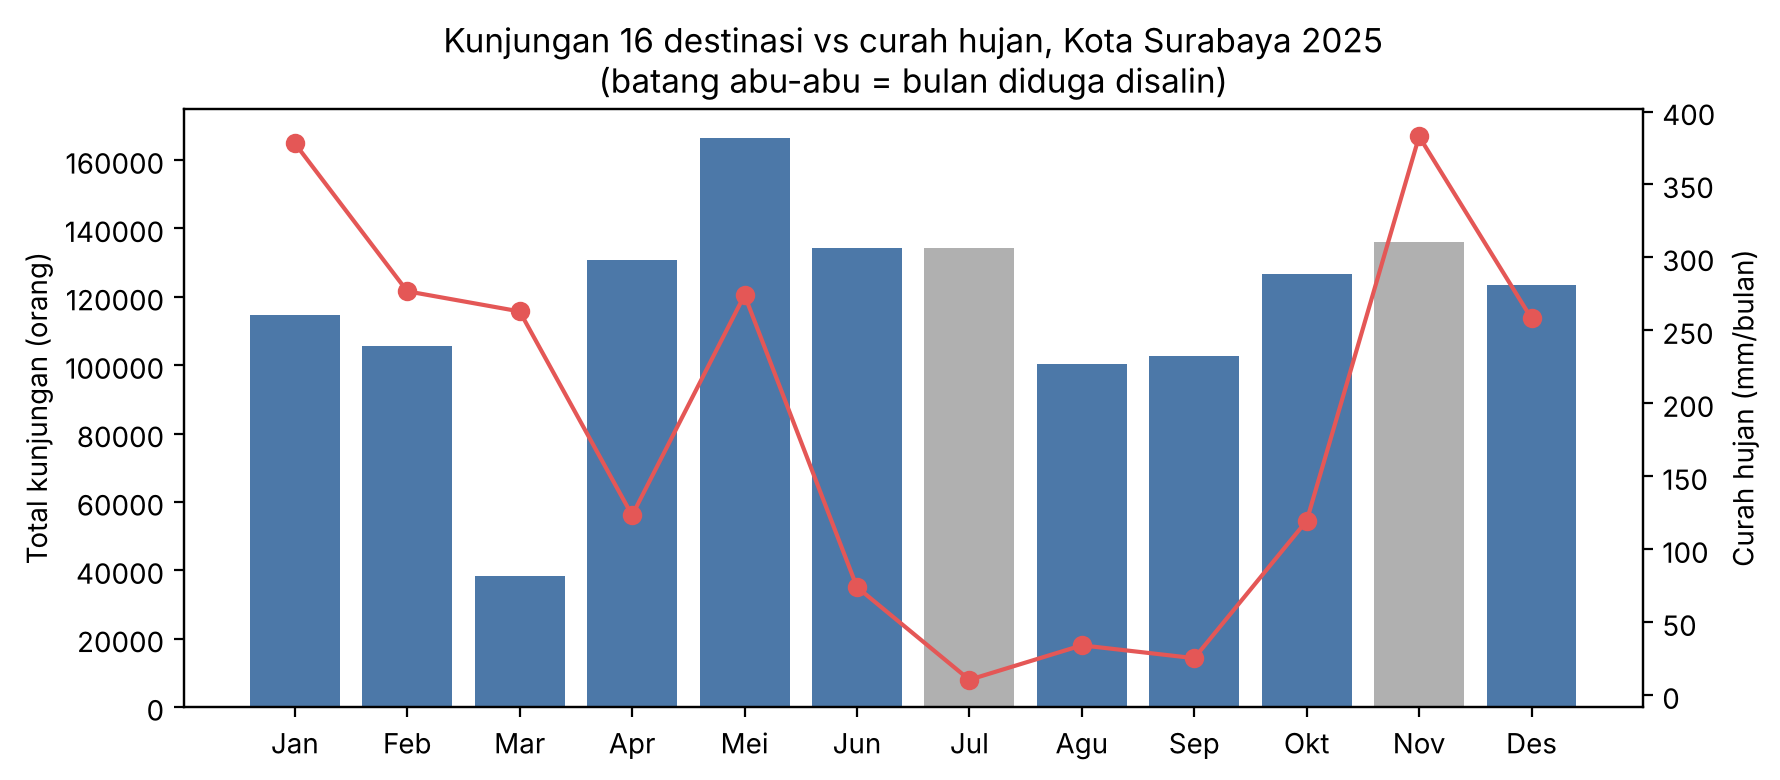

In [17]:
# ===== SOAL 5.3: presentasi, kunjungan bulanan vs cuaca (dengan dan tanpa bulan yang ditandai) =====
# Total kunjungan semua destinasi per bulan bersanding dengan cuaca (nilai cuaca sama untuk semua destinasi: 'first')
ringkas_bulanan = (gabungan_final.groupby(["bulan", "nama_bulan"]).agg(
    wisnus=("wisnus", "sum"), wisman=("wisman", "sum"), diduga_salinan=("diduga_salinan", "any"),
    curah_hujan_mm=("curah_hujan_mm", "first"), hari_hujan=("hari_hujan", "first"),
    suhu_rata2_c=("suhu_rata2_c", "first")).reset_index())
ringkas_bulanan["total_kunjungan"] = ringkas_bulanan["wisnus"] + ringkas_bulanan["wisman"]
display(ringkas_bulanan)

def spearman(df, x, y):
    """Korelasi Spearman = korelasi Pearson atas peringkat (tanpa scipy)."""
    r = df[[x, y]].rank()
    return round(r[x].corr(r[y]), 3)

# Bandingkan korelasi dengan dan tanpa bulan yang ditandai
tanpa = ringkas_bulanan[~ringkas_bulanan["diduga_salinan"]]
banding = pd.DataFrame([{"variabel_cuaca": v,
                         f"semua bulan (n={len(ringkas_bulanan)})": spearman(ringkas_bulanan, "total_kunjungan", v),
                         f"tanpa bulan bertanda (n={len(tanpa)})": spearman(tanpa, "total_kunjungan", v)}
                        for v in ["curah_hujan_mm", "hari_hujan", "suhu_rata2_c"]])
display(banding)
kol_semua, kol_tanpa = banding.columns[1], banding.columns[2]
berubah = [r["variabel_cuaca"] for _, r in banding.iterrows()
           if (r[kol_semua] > 0) != (r[kol_tanpa] > 0) or (r[kol_semua] == 0) != (r[kol_tanpa] == 0)]
print("Kesimpulan:", ("Arah hubungan kunjungan-cuaca BERUBAH untuk " + ", ".join(berubah) +
      " setelah bulan bertanda dikeluarkan, jadi kesimpulan bergantung pada bulan yang diduga disalin.") if berubah else
      "Arah hubungan kunjungan-cuaca TIDAK berubah setelah bulan bertanda dikeluarkan; hanya besarnya yang bergeser.",
      "Korelasi lemah dan n kecil: hanya indikatif, bukan sebab-akibat.")

# Grafik: total kunjungan (batang; abu-abu = bulan diduga disalin) dan curah hujan bulanan (garis)
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(ringkas_bulanan["nama_bulan"].str[:3], ringkas_bulanan["total_kunjungan"],
        color=["#B0B0B0" if t else "#4C78A8" for t in ringkas_bulanan["diduga_salinan"]])
ax1.set_ylabel("Total kunjungan (orang)")
ax1.set_title(f"Kunjungan {JUMLAH_DESTINASI} destinasi vs curah hujan, Kota Surabaya {TAHUN_DATA}\n(batang abu-abu = bulan diduga disalin)")
ax2 = ax1.twinx()
ax2.plot(ringkas_bulanan["nama_bulan"].str[:3], ringkas_bulanan["curah_hujan_mm"], color="#E45756", marker="o")
ax2.set_ylabel("Curah hujan (mm/bulan)")
fig.tight_layout()
plt.show()

## 6. Ringkasan akhir
Provenance semua sumber (`provenance.csv`), verifikasi ulang MD5 data mentah, log semua request web, dan daftar berkas keluaran. Pemeriksaan kelengkapan akhir dijalankan dengan `python scripts/verify_submission.py` di salinan repo.

In [18]:
# ===== RINGKASAN: provenance, verifikasi integritas MD5, log request, dan berkas keluaran =====
# Provenance semua sumber: setiap berkas di data/raw harus punya satu baris
df_prov = pd.DataFrame(PROVENANCE, columns=KOLOM_PROVENANCE)
df_prov.to_csv(BASE_DIR / "provenance.csv", index=False, encoding="utf-8")
berkas_raw = {str(p.relative_to(BASE_DIR)) for p in RAW_DIR.rglob("*")
              if p.is_file() and p.name != ".gitkeep" and not p.name.endswith(".akses")}
print("Disimpan: provenance.csv |", len(df_prov), "baris | berkas raw tanpa provenance:", sorted(berkas_raw - set(df_prov["path_lokal"])) or "tidak ada")
with pd.option_context("display.max_colwidth", 60):
    display(df_prov[["sumber_id", "peran", "katalog", "host_berkas", "tanggal_akses", "asal_tanggal_akses", "lisensi", "md5", "cara_perolehan"]])

# Verifikasi integritas: MD5 tiap berkas raw dihitung ulang dan dibandingkan dengan provenance
verifikasi = df_prov[["sumber_id", "path_lokal", "md5"]].copy()
verifikasi["md5_sekarang"] = [md5_file(BASE_DIR / p) for p in verifikasi["path_lokal"]]
verifikasi["tidak_berubah"] = verifikasi["md5"] == verifikasi["md5_sekarang"]
assert verifikasi["tidak_berubah"].all(), "Ada berkas raw yang berubah!"
display(verifikasi)

# Log request HTTP: bukti timeout, jeda, status code, dan percobaan ulang untuk setiap akses web
display(pd.DataFrame(LOG_REQUEST)) if LOG_REQUEST else print("Tidak ada request baru pada eksekusi ini (semua berkas mentah sudah ada).")

# Daftar berkas keluaran beserta ukurannya
keluaran = sorted(p for p in BASE_DIR.rglob("*") if p.is_file()
                  and (p.parts[len(BASE_DIR.parts)] == "data" or p.name in {"provenance.csv", "data_ethics_checklist.md"}))
pd.DataFrame({"berkas": [str(p.relative_to(BASE_DIR)) for p in keluaran], "ukuran_byte": [p.stat().st_size for p in keluaran]})

Disimpan: provenance.csv | 9 baris | berkas raw tanpa provenance: tidak ada


,sumber_id,peran,katalog,host_berkas,tanggal_akses,asal_tanggal_akses,lisensi,md5,cara_perolehan
0,A_data_go_id,sumber utama Soal 1,data.go.id,ckan.surabaya.go.id,2026-11-17,statis: tanggal unduhan manual (17 November 2026),Lisensi tidak dicantumkan pada tabel metadata halaman da...,2658a38dff0ec62756fbd1147fd6914a,unduhan manual lewat peramban oleh mahasiswa (tombol Dow...
1,A_ckan_verifikasi,verifikasi tautan unduhan sumber utama,data.go.id,ckan.surabaya.go.id,2026-11-18 22:11:13+0700,waktu eksekusi,Lisensi tidak dicantumkan pada tabel metadata halaman da...,2658a38dff0ec62756fbd1147fd6914a,skrip Python (etis_get) dengan User-Agent jujur; Crawl-d...
2,A_ckan_robots,bukti robots.txt host berkas,-,ckan.surabaya.go.id,2026-11-18 22:09:36+0700,waktu eksekusi,-,68cd7d0de0e975d0c54c5399b67b9ce6,skrip Python (etis_get)
3,B_open_meteo,sumber API Soal 3,-,archive-api.open-meteo.com,2026-11-18 22:11:17+0700,waktu eksekusi,CC-BY 4.0 sesuai halaman ketentuan Open-Meteo (https://o...,0fcf6e5491116a2c37e0890ffc8e2d64,"satu request API lewat etis_get (UA jujur, timeout, retr..."
4,B_html_lisensi,bukti lisensi Open-Meteo,-,open-meteo.com,2026-11-18 22:11:19+0700,waktu eksekusi,-,24918127445438ddfa8ec3f8ad6ec73b,etis_get setelah can_fetch()=True
5,B_html_ketentuan,bukti ketentuan Open-Meteo,-,open-meteo.com,2026-11-18 22:11:22+0700,waktu eksekusi,-,b5bdd4e3578da004ac805c909685e5a1,etis_get setelah can_fetch()=True
6,B_robots,bukti robots.txt Open-Meteo,-,open-meteo.com,2026-11-18 22:11:17+0700,waktu eksekusi,-,f77c87f977e0fcce05a6df46c885a129,etis_get
7,C_wikipedia_html,sumber scraping Soal 4,-,id.wikipedia.org,2026-11-18 22:11:25+0700,waktu eksekusi,CC BY-SA 4.0,2c9a9223810c7586ecd08b3ad81aa5c7,scraping lewat etis_get setelah can_fetch()=True; parse ...
8,C_robots,bukti robots.txt Wikipedia,-,id.wikipedia.org,2026-11-18 22:11:22+0700,waktu eksekusi,-,8dd94bf3d01cbb25e0af4e64c0485433,etis_get


,sumber_id,path_lokal,md5,md5_sekarang,tidak_berubah
0,A_data_go_id,data/raw/banyaknya-wisman-wisnus-2026.csv,2658a38dff0ec62756fbd1147fd6914a,2658a38dff0ec62756fbd1147fd6914a,True
1,A_ckan_verifikasi,data/raw/ckan_check/banyaknya-wisman-wisnus-20...,2658a38dff0ec62756fbd1147fd6914a,2658a38dff0ec62756fbd1147fd6914a,True
2,A_ckan_robots,data/raw/ckan_surabaya_robots.txt,68cd7d0de0e975d0c54c5399b67b9ce6,68cd7d0de0e975d0c54c5399b67b9ce6,True
3,B_open_meteo,data/raw/open_meteo_surabaya_harian_2025.json,0fcf6e5491116a2c37e0890ffc8e2d64,0fcf6e5491116a2c37e0890ffc8e2d64,True
4,B_html_lisensi,data/raw/open_meteo_lisensi.html,24918127445438ddfa8ec3f8ad6ec73b,24918127445438ddfa8ec3f8ad6ec73b,True
5,B_html_ketentuan,data/raw/open_meteo_ketentuan.html,b5bdd4e3578da004ac805c909685e5a1,b5bdd4e3578da004ac805c909685e5a1,True
6,B_robots,data/raw/open_meteo_robots.txt,f77c87f977e0fcce05a6df46c885a129,f77c87f977e0fcce05a6df46c885a129,True
7,C_wikipedia_html,data/raw/wikipedia_kecamatan_surabaya.html,2c9a9223810c7586ecd08b3ad81aa5c7,2c9a9223810c7586ecd08b3ad81aa5c7,True
8,C_robots,data/raw/wikipedia_id_robots.txt,8dd94bf3d01cbb25e0af4e64c0485433,8dd94bf3d01cbb25e0af4e64c0485433,True


Tidak ada request baru pada eksekusi ini (semua berkas mentah sudah ada).


,berkas,ukuran_byte
0,data/processed/.gitkeep,0
1,data/processed/cuaca_bulanan_surabaya.csv,692
2,data/processed/cuaca_harian_surabaya.csv,20207
3,data/processed/gabungan.csv,21586
4,data/processed/gabungan_metadata.json,4842
5,data/processed/kecamatan_surabaya.csv,2828
6,data/processed/kunjungan_bersih_bertanda.csv,28595
7,data/raw/.gitkeep,0
8,data/raw/banyaknya-wisman-wisnus-2026.csv,26881
9,data/raw/ckan_check/banyaknya-wisman-wisnus-20...,26881
